# Part 2 — Extension: Multi-Layer Perceptron (small neural network)

Same data, same split, same metrics as Part 1 — only the model is new.

**Why an MLP?**
1. **A different model family.** The paper uses tree models (Random Forest, XGBoost) and a linear model. An MLP learns a smooth non-linear function — neither threshold splits nor a straight line.
2. **Suits our features.** The 192 predictors are many correlated percentages (income bins, rent bins, occupations). An MLP can combine them into a few learned features; trees split on one variable at a time.
3. **A testable hypothesis.** On small tables, trees often match or beat neural nets. Either outcome is informative.
4. **Fair and cheap.** Trains in seconds, same imputation/scaling protocol, tuned on the validation set only.

**Protocol:** choose settings on the **validation set**, train on the training set, evaluate on the **test set once**.

## 1. Data and split (same as Part 1)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

df = pd.read_csv("gentrification_dataset.csv", index_col="GEO_ID")
LABELS = ["y_cost", "y_income"]

# Predictors = 188 tract features + 4 spatial features. Everything built from 2012-2016 data is excluded (it would leak the answer).
NOT_FEATURES = ["split", "y_cost", "y_income", "cost_change_2012_2016", "cost_change_2012_2016_cpi_adjusted",
                "y_cost_cpi_adjusted", "income_affluence_change_2012_2016", "income_change_scaled_0_100"]
FEATURES = [c for c in df.columns if c not in NOT_FEATURES]

# The split was made once when building the dataset (random 90/5/5 over tracts, seed 42)
tr, va, te = (df[df.split == s] for s in ("train", "val", "test"))
print(len(FEATURES), "features | train/val/test =", len(tr), len(va), len(te))

192 features | train/val/test = 7137 397 397


## 2. The model
Pipeline: fill missing values (training median) → scale → MLP. `hidden` = layer sizes, `alpha` = regularisation strength.

In [2]:
from sklearn.neural_network import MLPClassifier

def make_mlp(hidden, alpha, seed=42):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, max_iter=500,
                                       early_stopping=True, random_state=seed))

## 3. Choose settings on the validation set only
16 combinations, each trained on the training rows with 3 random seeds; we keep the one with the best average validation accuracy.

In [3]:
import itertools
grid = list(itertools.product([(32,), (64,), (64, 32), (128, 64)], [0.001, 0.01, 0.1, 1.0]))

rows = []
for label in LABELS:
    for hidden, alpha in grid:
        accs = [accuracy_score(va[label], make_mlp(hidden, alpha, s).fit(tr[FEATURES], tr[label]).predict(va[FEATURES]))
                for s in range(3)]
        rows.append(dict(response=label, hidden=str(hidden), alpha=alpha, val_accuracy=np.mean(accs)))
tuning = pd.DataFrame(rows)

best = {l: tuning[tuning.response == l].nlargest(1, "val_accuracy").iloc[0] for l in LABELS}
for l, r in best.items(): print(f"{l}: chosen hidden={r.hidden}, alpha={r.alpha}, validation accuracy={r.val_accuracy:.3f}")
tuning.pivot_table(index="hidden", columns=["response", "alpha"], values="val_accuracy").round(3)

y_cost: chosen hidden=(128, 64), alpha=0.001, validation accuracy=0.655
y_income: chosen hidden=(32,), alpha=0.1, validation accuracy=0.661


response  y_cost                      y_income                     
alpha      0.001  0.010  0.100  1.000    0.001  0.010  0.100  1.000
hidden                                                             
(128, 64)  0.655  0.651  0.653  0.648    0.641  0.641  0.651  0.657
(32,)      0.641  0.634  0.646  0.641    0.655  0.654  0.661  0.659
(64, 32)   0.642  0.631  0.632  0.636    0.639  0.643  0.647  0.650
(64,)      0.641  0.644  0.643  0.647    0.646  0.653  0.645  0.644

## 4. Train the chosen MLP and evaluate on the test set

In [4]:
def metrics(y, p):
    return dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p), recall=recall_score(y, p))

import ast
mlp, rows = {}, []
for label in LABELS:
    mlp[label] = make_mlp(ast.literal_eval(best[label].hidden), float(best[label].alpha))
    mlp[label].fit(tr[FEATURES], tr[label])                      # <-- training happens here
    rows.append(dict(response=label, model="MLP (extension)", **metrics(te[label], mlp[label].predict(te[FEATURES]))))

# Compare with the Part 1 models (run Part 1 first: it saves part1_results.csv)
results = pd.concat([pd.read_csv("part1_results.csv"), pd.DataFrame(rows)])
order = ["Majority-class baseline", "L1 Logistic Reg.", "Random Forest", "XGBoost", "Ensemble (majority vote)", "MLP (extension)"]
results.pivot_table(index="model", columns="response", values=["accuracy", "precision", "recall"]).loc[order].round(3)

accuracy          precision          recall         
response                   y_cost y_income    y_cost y_income y_cost y_income
model                                                                        
Majority-class baseline     0.494    0.660     0.494    0.660  1.000    1.000
L1 Logistic Reg.            0.678    0.660     0.652    0.660  0.745    1.000
Random Forest               0.678    0.693     0.642    0.703  0.786    0.924
XGBoost                     0.698    0.673     0.671    0.714  0.760    0.840
Ensemble (majority vote)    0.685    0.700     0.658    0.700  0.755    0.954
MLP (extension)             0.647    0.652     0.618    0.691  0.750    0.855

## 5. MLP confusion matrices (test set)

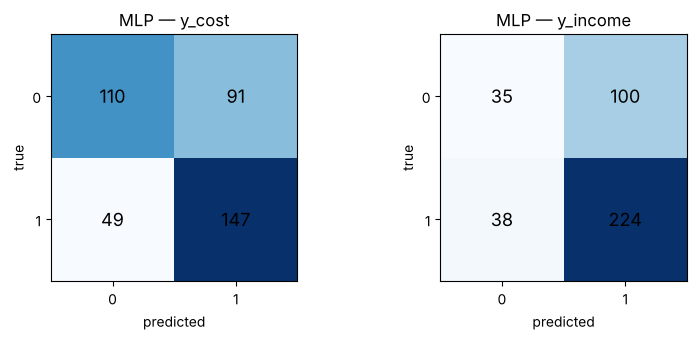

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, label in zip(axes, LABELS):
    cm = confusion_matrix(te[label], mlp[label].predict(te[FEATURES]), labels=[0, 1]); ax.imshow(cm, cmap="Blues")
    for (a, b), v in np.ndenumerate(cm): ax.text(b, a, v, ha="center", va="center", fontsize=13)
    ax.set_title(f"MLP — {label}"); ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

## 6. Is the MLP result just luck of one random start?
Neural networks start from random weights. Same data and settings, 10 different seeds:

In [6]:
for label in LABELS:
    accs = [accuracy_score(te[label], make_mlp(ast.literal_eval(best[label].hidden), float(best[label].alpha), s)
                           .fit(tr[FEATURES], tr[label]).predict(te[FEATURES])) for s in range(10)]
    print(f"{label}: test accuracy over 10 seeds = {np.mean(accs):.3f} +/- {np.std(accs):.3f}  (min {min(accs):.3f}, max {max(accs):.3f})")

y_cost: test accuracy over 10 seeds = 0.663 +/- 0.010  (min 0.645, max 0.685)


y_income: test accuracy over 10 seeds = 0.664 +/- 0.011  (min 0.647, max 0.678)


## Takeaway
The MLP does clearly better than the majority-class baseline on `y_cost`, but it does **not** beat the tree models; on `y_income` every model is only slightly above the baseline. Differences of 1–3 points are within the ±4.6-point noise of a 397-tract test set. A plausible reason: tract data has threshold-like patterns that trees capture well, and ~7,000 rows leave a neural network little room to find extra structure.